In [10]:
# Importaciones principales
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuracion visual para graficos de ingenieria
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de NumPy:  {np.__version__}")

Versión de Pandas: 3.0.6
Versión de NumPy:  2.4.6


In [11]:
def resolver_ruta_archivo(nombre_archivo="air_quality_telemetry.csv") -> Path:
    """
    Localiza de manera robusta un archivo de datos buscando en los directorios
    padre del proyecto o descargándolo si es necesario.
    """
    # Posibles ubicaciones relativas comunes en la estructura del curso
    candidatos = [
        Path("data") / nombre_archivo,
        Path("..") / "data" / nombre_archivo,
        Path("..") / ".." / "data" / nombre_archivo,
        Path("examples") / "data" / nombre_archivo,
    ]
    
    for ruta in candidatos:
        if ruta.exists():
            print(f"[OK] Archivo encontrado localmente en: {ruta.resolve()}")
            return ruta.resolve()
            
    # Fallback: intentar crear data/ en la raiz detectada y descargar
    print("[INFO] Archivo no encontrado localmente. Descargando dataset de respaldo...")
    url_fuente = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
    ruta_destino = Path("data") / nombre_archivo
    ruta_destino.parent.mkdir(parents=True, exist_ok=True)
    
    import urllib.request
    urllib.request.urlretrieve(url_fuente, ruta_destino)
    print(f"[OK] Dataset descargado exitosamente en: {ruta_destino.resolve()}")
    return ruta_destino.resolve()

ruta_datos = resolver_ruta_archivo("air_quality_telemetry.csv")

[OK] Archivo encontrado localmente en: C:\Users\crist\Desktop\laboratorios\lab5_taller5\data\air_quality_telemetry.csv


In [12]:
def auditar_calidad_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """
    Genera una tabla de diagnostico de calidad de datos por columna,
    incluyendo tipos de datos, cantidad de registros validos, nulos
    y el porcentaje exacto de perdida de informacion.
    """
    total_filas = len(df)
    conteo_nulos = df.isna().sum()
    porcentaje_nulos = (conteo_nulos / total_filas) * 100.0
    
    auditoria = pd.DataFrame({
        'Tipo de Dato': df.dtypes,
        'Valores No Nulos': df.notna().sum(),
        'Valores Nulos (NaN)': conteo_nulos,
        'Pérdida (%)': porcentaje_nulos.round(2),
        'Valores Únicos': df.nunique()
    })
    return auditoria

def resumen_memoria_dataframe(df: pd.DataFrame) -> None:
    """
    Imprime el uso total de memoria RAM del DataFrame en Megabytes.
    """
    uso_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    print(f"Uso total estimado en memoria RAM: {uso_mb:.2f} MB")

In [19]:
# 1.1 Cargar el CSV
df_crudo = pd.read_csv(ruta_datos)

# 1.2 Crear la columna datetime combinando year, month, day y hour
df_crudo['datetime'] = pd.to_datetime(df_crudo[['year', 'month', 'day', 'hour']])

# 1.3 Usar datetime como índice
df = df_crudo.set_index('datetime')

df.tail()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
datetime,,,,,,,,,,,,,
2014-12-31 19:00:00,43820,2014,12,31,19,8.0,-23,-2.0,1034.0,NW,231.97,0,0
2014-12-31 20:00:00,43821,2014,12,31,20,10.0,-22,-3.0,1034.0,NW,237.78,0,0
2014-12-31 21:00:00,43822,2014,12,31,21,10.0,-22,-3.0,1034.0,NW,242.70,0,0
2014-12-31 22:00:00,43823,2014,12,31,22,8.0,-22,-4.0,1034.0,NW,246.72,0,0
2014-12-31 23:00:00,43824,2014,12,31,23,12.0,-21,-3.0,1034.0,NW,249.85,0,0


In [20]:
# 1.4 Auditoría de calidad y memoria
tabla_diagnostico = auditar_calidad_dataframe(df)
display(tabla_diagnostico)
resumen_memoria_dataframe(df)

# 1.5 Estadísticas de las variables numéricas
df.describe()

,Tipo de Dato,Valores No Nulos,Valores Nulos (NaN),Pérdida (%),Valores Únicos
No,int64,43824,0,0.00,43824
year,int64,43824,0,0.00,5
month,int64,43824,0,0.00,12
day,int64,43824,0,0.00,31
hour,int64,43824,0,0.00,24
pm2.5,float64,41757,2067,4.72,581
DEWP,int64,43824,0,0.00,69
TEMP,float64,43824,0,0.00,64
PRES,float64,43824,0,0.00,60
cbwd,str,43824,0,0.00,4


Dimensiones: 43,824 filas x 13 columnas
Uso total estimado en memoria RAM: 6.81 MB


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,41757.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,21912.500000,2012.000000,6.523549,15.727820,11.500000,98.613215,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,12651.043435,1.413842,3.448572,8.799425,6.922266,92.050387,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,1.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,10956.750000,2011.000000,4.000000,8.000000,5.750000,29.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,21912.500000,2012.000000,7.000000,16.000000,11.500000,72.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,32868.250000,2013.000000,10.000000,23.000000,17.250000,137.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,43824.000000,2014.000000,12.000000,31.000000,23.000000,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


¿Qué canal de telemetría presenta valores nulos y qué porcentaje del total representan? ¿Por qué sería un error grave para un análisis de series de tiempo utilizar df.dropna() en este caso?

el valor que presenta valores nulos es el "pm2.5" con una perdida de 4.2%.
No es posible utilizar dropna() ya que elimina valores borrando filas, por ende puede eliminar datos utiles.

In [15]:
df_limpio = df.copy()
df_limpio['pm2.5_limpio'] = df_limpio['pm2.5'].interpolate(method='linear').bfill()
nulos_restantes = df_limpio['pm2.5_limpio'].isna().sum()
print(f"valores nulos despues de la interpolazion: {nulos_restantes}")
assert nulos_restantes == 0, "Aún existen valores nulos después de la interpolación."

valores nulos despues de la interpolazion: 0


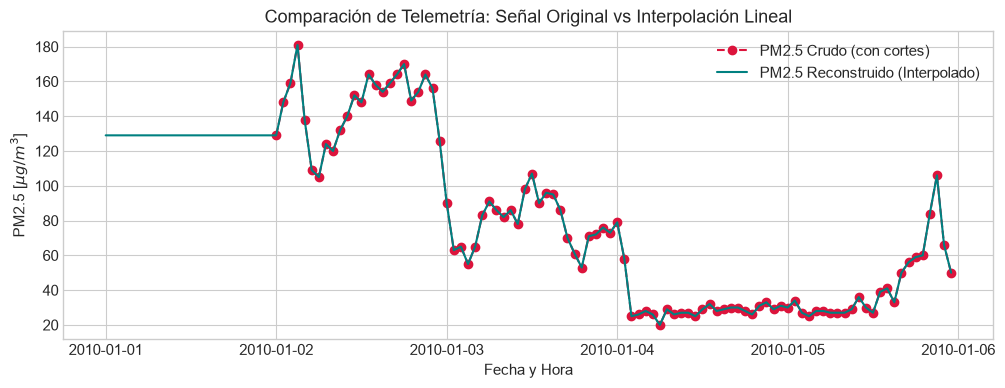

In [16]:
ventana_muestra = slice('2010-01-01', '2010-01-05')
plt.figure(figsize=(12, 4))
plt.plot(df.loc[ventana_muestra, 'pm2.5'], 'o--', label='PM2.5 Crudo (con cortes)', color='crimson')
plt.plot(df_limpio.loc[ventana_muestra, 'pm2.5_limpio'], '-', label='PM2.5 Reconstruido (Interpolado)', color='teal')
plt.title('Comparación de Telemetría: Señal Original vs Interpolación Lineal')
plt.xlabel('Fecha y Hora')
plt.ylabel('PM2.5 [$\\mu g/m^3$]')
plt.legend()
plt.show()

In [17]:
# 3.1 Condiciones físicas por separado
condicion_pm = df_limpio['pm2.5_limpio'] > 150.0
condicion_frio = df_limpio['TEMP'] < 0.0

# Se combinan con & (ambas deben cumplirse a la vez)
mascara_emergencia = condicion_pm & condicion_frio

# 3.2 Aplicar la máscara
df_critico = df_limpio[mascara_emergencia]
print(f"Total de horas en condición crítica registradas: {len(df_critico)}")
df_enero2013 = df_limpio.loc['2013-01-01':'2013-01-31']
print(f"Horas en enero 2013: {len(df_enero2013)}")

# Horas críticas dentro de enero 2013
horas_criticas_enero = mascara_emergencia.loc['2013-01-01':'2013-01-31'].sum()
print(f"Horas de emergencia ambiental en enero 2013: {horas_criticas_enero}")

Total de horas en condición crítica registradas: 2301
Horas en enero 2013: 744
Horas de emergencia ambiental en enero 2013: 341


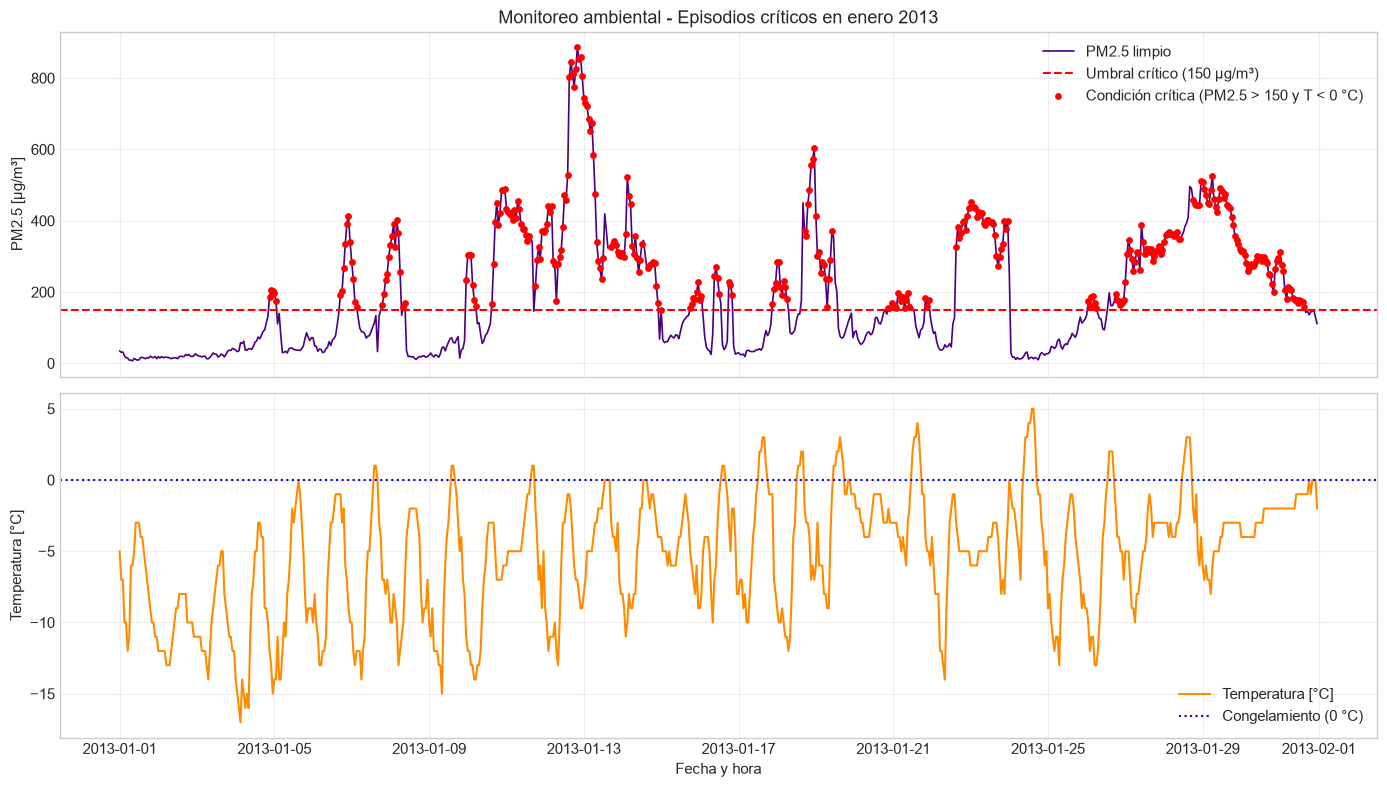

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Horas críticas dentro de enero 2013
criticos_enero = df_enero2013[mascara_emergencia.loc['2013-01-01':'2013-01-31']]

# Panel 1: PM2.5, umbral y puntos críticos
ax1.plot(df_enero2013.index, df_enero2013['pm2.5_limpio'],
         color='indigo', lw=1.2, label='PM2.5 limpio')
ax1.axhline(150, color='red', linestyle='--', label='Umbral crítico (150 µg/m³)')
ax1.scatter(criticos_enero.index, criticos_enero['pm2.5_limpio'],
            color='red', s=15, zorder=3, label='Condición crítica (PM2.5 > 150 y T < 0 °C)')
ax1.set_ylabel('PM2.5 [µg/m³]')
ax1.set_title('Monitoreo ambiental - Episodios críticos en enero 2013')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Panel 2: temperatura
ax2.plot(df_enero2013.index, df_enero2013['TEMP'],
         color='darkorange', label='Temperatura [°C]')
ax2.axhline(0, color='blue', linestyle=':', label='Congelamiento (0 °C)')
ax2.set_ylabel('Temperatura [°C]')
ax2.set_xlabel('Fecha y hora')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Conclusión Técnica del Estudiante
los peaks de PM2.5 pasan casi siempre en los días más fríos debido a que cuando hace mucho frío la gente usa más calefacción, así que se emite más contaminación.
se usa esta interpolacion en especifco "interpolate(method='linear')" ya que básicamente une el último valor medido antes del hueco con el primero que aparece después y reparte los valores intermedios en línea recta, permitiendo encontrar los valores nulos.